# Практическая работа № 6. Классификация текстов

**Вариант:** B

**Цель работы:** освоить предобработку текстов, преобразование текстов в числовые признаки и построение классификатора.

**Используемые методы:** очистка текста, токенизация, TF-IDF, Multinomial Naive Bayes.

**Инструменты:** Python, Pandas, Scikit-learn, Matplotlib.

## 1. Подготовка библиотек

Для выполнения работы используются библиотеки Python.

- Pandas — для работы с таблицами.
- Scikit-learn — для разделения данных, векторизации, обучения модели и оценки качества.
- Matplotlib — для отображения матрицы ошибок.
- Re — для очистки текста с помощью регулярных выражений.

In [2]:
!python -m pip install pandas scikit-learn matplotlib

In [3]:
import pandas as pd
import re
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

## 2. Подготовка текстового корпуса

Для классификации используется набор коротких отзывов о фильмах и книгах.

Каждый отзыв имеет метку класса:
- `positive` — положительный отзыв;
- `negative` — отрицательный отзыв.

Данные сохраняются в таблицу Pandas. Столбец `text` содержит текст, а столбец `label` содержит правильный класс.

Учебный корпус используется для демонстрации полного процесса классификации текстов.

In [13]:

texts = [
    "Фильм очень хороший и интересный",
    "Мне понравился этот фильм",
    "Отличная игра актеров",
    "Фильм просто замечательный",
    "Очень красивый и добрый фильм",
    "Сюжет интересный и захватывающий",
    "Мне очень понравилась история",
    "Прекрасный фильм для вечера",
    "Актеры сыграли великолепно",
    "Фильм оставил хорошие впечатления",
    "Книга очень интересная",
    "Мне понравилась эта книга",
    "Отличный сюжет и хорошие герои",
    "Прекрасная история и концовка",
    "Это лучший фильм",
    "Игра актеров просто отличная",
    "Смотреть было интересно",
    "Фильм подарил хорошее настроение",
    "Очень качественная работа",
    "Я доволен просмотром",
    "Фильм очень плохой и скучный",
    "Мне не понравился этот фильм",
    "Ужасная игра актеров",
    "Фильм просто отвратительный",
    "Сюжет скучный и неинтересный",
    "Мне совершенно не понравилась история",
    "Плохой фильм для вечера",
    "Актеры сыграли ужасно",
    "Фильм оставил плохие впечатления",
    "Книга очень скучная",
    "Мне не понравилась эта книга",
    "Плохой сюжет и слабые герои",
    "Ужасная история и концовка",
    "Это худший фильм",
    "Игра актеров просто ужасная",
    "Смотреть было скучно",
    "Фильм испортил настроение",
    "Очень низкое качество",
    "Я недоволен просмотром",
    "Фильм не стоит потраченного времени",
    "Мне понравилась музыка",
    "Музыка в фильме прекрасная",
    "Отличная работа режиссера",
    "Фильм выглядит красиво",
    "Сюжет оказался лучше ожиданий",
    "Очень плохая музыка",
    "Режиссер плохо справился",
    "Картинка выглядит ужасно",
    "Сюжет оказался хуже ожиданий",
    "Не рекомендую этот фильм",
    "Рекомендую посмотреть этот фильм",
    "Фильм не был интересным",
    "Фильм был не плохим",
    "Книга оказалась скучной",
    "Книга оказалась прекрасной",
    "Мне было скучно смотреть",
    "Мне было приятно смотреть",
    "Очень разочарован этим фильмом",
    "Я получил удовольствие от фильма",
    "Фильм совершенно не оправдал ожиданий",
    "Фильм превзошел все ожидания"
]

labels = (
    ["positive"] * 20
    + ["negative"] * 20
    + [
        "positive", "positive", "positive", "positive", "positive",
        "negative", "negative", "negative", "negative", "negative",
        "positive", "negative", "negative", "negative", "negative",
        "positive", "negative", "positive", "negative", "positive", "positive"
    ]
)
print("Количество текстов:", len(texts))
print("Количество меток:", len(labels))

assert len(texts) == len(labels), "Количество текстов и меток не совпадает!"

data = {
    "text": texts,
    "label": labels
}

df = pd.DataFrame(data)

print("Размер датасета:", df.shape)
print(df["label"].value_counts())
print(df.head())

Количество текстов: 61
Количество меток: 61
Размер датасета: (61, 2)
label
negative    31
positive    30
Name: count, dtype: int64
                               text     label
0  Фильм очень хороший и интересный  positive
1         Мне понравился этот фильм  positive
2             Отличная игра актеров  positive
3        Фильм просто замечательный  positive
4     Очень красивый и добрый фильм  positive


## 3. Предобработка текста

На этом этапе создаётся функция очистки текста.

Она выполняет следующие действия:
1. Переводит текст в нижний регистр.
2. Удаляет пунктуацию.
3. Удаляет цифры.
4. Разделяет текст на отдельные слова.
5. Удаляет выбранные стоп-слова.

Отрицания, например «не», сохраняются, потому что они могут менять тональность отзыва.

Стемминг и лемматизация в этой работе не используются, чтобы сохранить простой вариант обработки текста.

In [14]:
stop_words = {
    "и", "в", "во", "на", "с", "со", "к", "по", "за",
    "из", "у", "о", "об", "от", "до", "для", "же",
    "это", "этот", "эта", "мне", "я", "было", "был",
    "была", "очень", "просто"
}

def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^\w\s]", " ", text)
    text = re.sub(r"\d+", " ", text)

    words = text.split()
    words = [word for word in words if word not in stop_words]

    return " ".join(words)

## 4. Проверка результатов предобработки

Применим функцию очистки ко всем отзывам и сравним исходные тексты с обработанными.

Это позволяет проверить, что ненужные символы и выбранные стоп-слова удалены, а значимые слова сохранены.

In [15]:
df["clean_text"] = df["text"].apply(clean_text)

print(df[["text", "clean_text"]].head(10))

                                text                         clean_text
0   Фильм очень хороший и интересный           фильм хороший интересный
1          Мне понравился этот фильм                   понравился фильм
2              Отличная игра актеров              отличная игра актеров
3         Фильм просто замечательный                фильм замечательный
4      Очень красивый и добрый фильм              красивый добрый фильм
5   Сюжет интересный и захватывающий     сюжет интересный захватывающий
6      Мне очень понравилась история                понравилась история
7        Прекрасный фильм для вечера            прекрасный фильм вечера
8         Актеры сыграли великолепно         актеры сыграли великолепно
9  Фильм оставил хорошие впечатления  фильм оставил хорошие впечатления


## 5. Разделение данных

Данные разделяются на обучающую и тестовую выборки.

- 75% данных используется для обучения.
- 25% данных используется для проверки модели.

Параметр `random_state=42` обеспечивает воспроизводимость результата, а `stratify=y` сохраняет пропорции классов.

Разделение проводится до векторизации, чтобы избежать утечки данных.

## 5. Разделение данных

Данные разделяются на обучающую и тестовую выборки.

- 75% данных используется для обучения.
- 25% данных используется для проверки модели.

Параметр `random_state=42` обеспечивает воспроизводимость результата, а `stratify=y` сохраняет пропорции классов.

Разделение проводится до векторизации, чтобы избежать утечки данных.

In [16]:
X = df["clean_text"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Обучающая выборка:", len(X_train))
print("Тестовая выборка:", len(X_test))

Обучающая выборка: 45
Тестовая выборка: 16


## 6. Векторизация текста с помощью TF-IDF

TF-IDF преобразует текст в числовые признаки.

Слова получают веса в зависимости от их значимости для документов. Часто встречающиеся слова могут иметь меньший вес, а более характерные для отдельных отзывов слова — больший.

Параметры:
- `min_df=1` — слово должно встретиться хотя бы в одном обучающем документе.
- `max_df=0.95` — исключаются слова, встречающиеся более чем в 95% обучающих документов.

Векторизатор обучается на тренировочных текстах. Тестовые тексты преобразуются без повторного обучения векторизатора.

In [17]:
vectorizer = TfidfVectorizer(
    min_df=1,
    max_df=0.95
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("Размер обучающей матрицы:", X_train_tfidf.shape)
print("Размер тестовой матрицы:", X_test_tfidf.shape)
print("Количество признаков:", len(vectorizer.vocabulary_))

Размер обучающей матрицы: (45, 75)
Размер тестовой матрицы: (16, 75)
Количество признаков: 75


## 7. Обучение модели Multinomial Naive Bayes

Для классификации используется алгоритм Multinomial Naive Bayes.

Он оценивает вероятности принадлежности текста к каждому классу на основе признаков и обучающих меток.

Метод `fit()` обучает модель, а `predict()` предсказывает классы для тестовых текстов.

In [18]:
model = MultinomialNB()

model.fit(X_train_tfidf, y_train)

y_pred = model.predict(X_test_tfidf)

print("Обучение завершено")
print("Первые 10 предсказаний:", y_pred[:10])

Обучение завершено
Первые 10 предсказаний: ['negative' 'positive' 'negative' 'negative' 'positive' 'negative'
 'negative' 'positive' 'negative' 'negative']


## 8. Оценка качества классификации

Для оценки модели используются четыре метрики:

- **Accuracy** — доля всех правильных предсказаний.
- **Precision** — доля правильных положительных предсказаний.
- **Recall** — доля найденных положительных отзывов.
- **F1-score** — баланс Precision и Recall.

Дополнительно выводится отчёт с метриками для каждого класса.

Значения метрик рассчитываются по результатам предсказаний на тестовой выборке.

In [20]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred,
    pos_label="positive",
    zero_division=0
)

recall = recall_score(
    y_test, y_pred,
    pos_label="positive",
    zero_division=0
)

f1 = f1_score(
    y_test, y_pred,
    pos_label="positive",
    zero_division=0
)

print("Accuracy:", round(accuracy, 3))
print("Precision:", round(precision, 3))
print("Recall:", round(recall, 3))
print("F1-score:", round(f1, 3))

print("\nПодробный отчет:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.562
Precision: 0.6
Recall: 0.375
F1-score: 0.462

Подробный отчет:
              precision    recall  f1-score   support

    negative       0.55      0.75      0.63         8
    positive       0.60      0.38      0.46         8

    accuracy                           0.56        16
   macro avg       0.57      0.56      0.55        16
weighted avg       0.57      0.56      0.55        16



## 9. Матрица ошибок

Матрица ошибок показывает, сколько отзывов модель классифицировала правильно и неправильно.

- **TN** — отрицательный отзыв правильно определён как отрицательный.
- **FP** — отрицательный отзыв ошибочно определён как положительный.
- **FN** — положительный отзыв ошибочно определён как отрицательный.
- **TP** — положительный отзыв правильно определён как положительный.

Матрица помогает понять, какие виды ошибок встречаются чаще.

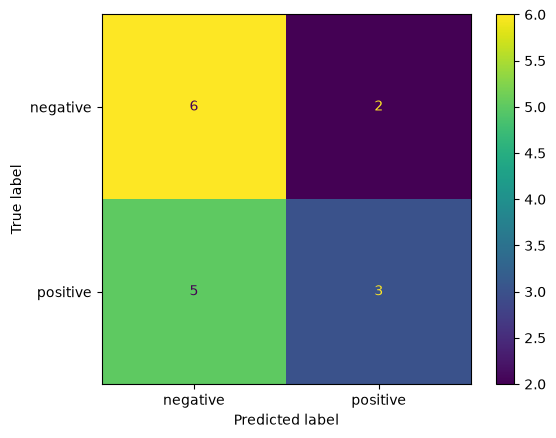

In [21]:
labels = ["negative", "positive"]

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=labels
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

display.plot()
plt.show()

## 10. Поиск ошибочных предсказаний

Сравним настоящие и предсказанные метки тестовых отзывов.

В отдельную таблицу попадут только те тексты, для которых модель предсказала неправильный класс.

Это позволит перейти от общей оценки качества к анализу конкретных ошибок.

In [23]:
errors = pd.DataFrame({
    "text": X_test.values,
    "true_label": y_test.values,
    "predicted_label": y_pred
})

errors = errors[
    errors["true_label"] != errors["predicted_label"]
]

print("Количество ошибок:", len(errors))
from IPython.display import display as show_table

show_table(errors.head(5))

Количество ошибок: 7


,text,true_label,predicted_label
0,лучший фильм,positive,negative
2,фильм совершенно не оправдал ожиданий,positive,negative
6,рекомендую посмотреть фильм,positive,negative
7,плохая музыка,negative,positive
10,разочарован этим фильмом,positive,negative


## 11. Анализ ошибок модели

Ошибки классификации могут возникать по следующим причинам:

1. **Отрицания.** Слово «не» может менять тональность всего предложения.
2. **Смешанная оценка.** В одном отзыве могут присутствовать как положительные, так и отрицательные слова.
3. **Недостаток данных.** Модель могла редко встречать похожие выражения при обучении.
4. **Разный смысл слов.** Одно слово может использоваться в разных контекстах.
5. **Разные формы слов.** Например, «понравился» и «понравилась» могут восприниматься как отдельные признаки.

Для каждой ошибки необходимо указать текст, правильный класс, предсказанный класс и возможную причину.

Причины формулируются после просмотра реальных ошибочных предсказаний.

In [24]:
for i, row in enumerate(errors.head(5).itertuples(index=False), start=1):
    print(f"Ошибка {i}")
    print("Текст:", row.text)
    print("Правильный класс:", row.true_label)
    print("Предсказанный класс:", row.predicted_label)
    print("-" * 40)

Ошибка 1
Текст: лучший фильм
Правильный класс: positive
Предсказанный класс: negative
----------------------------------------
Ошибка 2
Текст: фильм совершенно не оправдал ожиданий
Правильный класс: positive
Предсказанный класс: negative
----------------------------------------
Ошибка 3
Текст: рекомендую посмотреть фильм
Правильный класс: positive
Предсказанный класс: negative
----------------------------------------
Ошибка 4
Текст: плохая музыка
Правильный класс: negative
Предсказанный класс: positive
----------------------------------------
Ошибка 5
Текст: разочарован этим фильмом
Правильный класс: positive
Предсказанный класс: negative
----------------------------------------


### Анализ полученных ошибок

**Ошибка 1.** 
Текст: лучший фильм
Правильный класс: positive
Предсказанный класс: negative
**Ошибка 2.** 
Текст: фильм совершенно не оправдал ожиданий
Правильный класс: positive
Предсказанный класс: negative
**Ошибка 3.**
Текст: рекомендую посмотреть фильм
Правильный класс: positive
Предсказанный класс: negative
**Ошибка 4.** 
Текст: плохая музыка
Правильный класс: negative
Предсказанный класс: positive
**Ошибка 5.** 
Текст: разочарован этим фильмом
Правильный класс: positive
Предсказанный класс: negative


## 12. Выводы

В ходе практической работы был реализован базовый процесс классификации текстов.

Сначала тексты были очищены от пунктуации, цифр и выбранных стоп-слов. Затем данные были разделены на обучающую и тестовую выборки.

Для преобразования текстов в числовые признаки использовался TF-IDF. После этого был обучен классификатор Multinomial Naive Bayes.

Качество модели оценивалось с помощью Accuracy, Precision, Recall и F1-score. Также была построена матрица ошибок и выполнен анализ неверных предсказаний.

Таким образом, были изучены основные этапы классификации текстов и возможные причины ошибок модели.

## 13. Формулы, использованные в работе

### 1. TF-IDF

\[
TFIDF(t,d)=TF(t,d)\cdot IDF(t)
\]

TF-IDF показывает важность слова для конкретного документа.

- \(TF(t,d)\) — частота слова в документе.
- \(IDF(t)\) — показатель редкости слова во всём корпусе.

Часто встречающиеся во всех документах слова обычно получают меньший вес, чем более характерные слова.

### 2. Теорема Байеса

\[
P(C\mid X)=\frac{P(X\mid C)P(C)}{P(X)}
\]

Формула используется для вычисления вероятности принадлежности текста к определённому классу.

- \(C\) — класс текста.
- \(X\) — признаки текста.
- \(P(C)\) — исходная вероятность класса.
- \(P(X\mid C)\) — вероятность признаков при данном классе.
- \(P(C\mid X)\) — вероятность класса при известных признаках.

### 3. Наивный байесовский классификатор

\[
P(C\mid X)\propto P(C)\prod_{i=1}^{n}P(x_i\mid C)
\]

Классификатор оценивает вероятность класса на основе отдельных признаков. При этом предполагается, что признаки условно независимы друг от друга при известном классе.

### 4. Accuracy

\[
Accuracy=\frac{TP+TN}{TP+TN+FP+FN}
\]

Показывает долю всех правильных предсказаний.

### 5. Precision

\[
Precision=\frac{TP}{TP+FP}
\]

Показывает, какая доля предсказанных положительных отзывов действительно является положительной.

### 6. Recall

\[
Recall=\frac{TP}{TP+FN}
\]

Показывает, какую долю настоящих положительных отзывов модель смогла найти.

### 7. F1-score

\[
F1=2\cdot\frac{Precision\cdot Recall}{Precision+Recall}
\]

Это гармоническое среднее Precision и Recall. Чем выше F1-score, тем лучше сбалансированы эти две метрики.

### Заключение

TF-IDF используется для преобразования текста в числовые признаки, наивный байесовский классификатор — для определения класса текста, а метрики — для оценки качества предсказаний.

## 14. Сохранение результатов

После выполнения всех ячеек необходимо сохранить ноутбук.

Проверяем, что:
- все ячейки выполнились без ошибок;
- показан пример очистки текста;
- выведены размеры матриц TF-IDF;
- показаны метрики качества;
- построена матрица ошибок;
- выполнен анализ фактических ошибок модели.

После проверки файл можно загрузить в GitHub.

## 15. Загрузка практической работы на GitHub

Для хранения результатов используется репозиторий `Machine_Learning`.

Ноутбук сохраняется в папке `notebooks`. После сохранения изменения добавляются в Git, фиксируются коммитом и отправляются на GitHub.

После загрузки необходимо открыть репозиторий и убедиться, что файл доступен.